## Analysing the cleaned data

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [4]:
PROJECT_ROOT = Path.cwd()
CLEAN_FILE = PROJECT_ROOT / "data" / "Ecommerce_Consumer_Behavior_Analysis_Clean.csv"

sns.set_theme(style="whitegrid", palette="deep")

In [7]:
df = pd.read_csv(CLEAN_FILE, encoding="utf-8-sig", parse_dates=["Time_of_Purchase"])

print(f"Loded: {CLEAN_FILE.name}")
print(f"Rows and Columns: {df.shape}")
print(f"Remaining Missing Values: {df.isna().sum().sum():,}")
display(df.head())


Loded: Ecommerce_Consumer_Behavior_Analysis_Clean.csv
Rows and Columns: (1000, 28)
Remaining Missing Values: 0


,Customer_ID,Age,Gender,Income_Level,Marital_Status,Education_Level,Occupation,Location,Purchase_Category,Purchase_Amount,...,Customer_Satisfaction,Engagement_with_Ads,Device_Used_for_Shopping,Payment_Method,Time_of_Purchase,Discount_Used,Customer_Loyalty_Program_Member,Purchase_Intent,Shipping_Preference,Time_to_Decision
0,37-611-6911,22,Female,Middle,Married,Bachelor's,Middle,Évry,Gardening & Outdoors,333.80,...,7,Unknown,Tablet,Credit Card,2024-03-01,True,False,Need-based,No Preference,2
1,29-392-9296,49,Male,High,Married,High School,High,Huocheng,Food & Beverages,222.22,...,5,High,Tablet,PayPal,2024-04-16,True,False,Wants-based,Standard,6
2,84-649-5117,24,Female,Middle,Single,Master's,High,Huzhen,Office Supplies,426.22,...,7,Low,Smartphone,Debit Card,2024-03-15,True,True,Impulsive,No Preference,3
3,48-980-6078,29,Female,Middle,Single,Master's,Middle,Wiwilí,Home Appliances,101.31,...,1,Unknown,Smartphone,Other,2024-10-04,True,True,Need-based,Express,10
4,91-170-9072,33,Female,Middle,Widowed,High School,Middle,Nara,Furniture,211.70,...,10,Unknown,Smartphone,Debit Card,2024-01-30,False,False,Wants-based,No Preference,4


In [8]:
total_sales = df["Purchase_Amount"].sum()
avg_order_value = df["Purchase_Amount"].mean()
median_order_value = df["Purchase_Amount"].median()
customer_count = df["Customer_ID"].nunique()
date_start = df["Time_of_Purchase"].min()
date_end = df["Time_of_Purchase"].max()

print(f"Customer records: {len(df):,}")
print(f"Unique Customer IDs: {customer_count:,}")
print(f"Recorded total Purchase amount: ${total_sales:,.2f}")
print(f"Average Purchase amount: ${avg_order_value:,.2f}")
print(f"Median Purchase amount: ${median_order_value:,.2f}")
print(f"Purchase date range: {date_start:%b %d, %Y} to {date_end:%b %d, %Y}")

Customer records: 1,000
Unique Customer IDs: 1,000
Recorded total Purchase amount: $275,063.88
Average Purchase amount: $275.06
Median Purchase amount: $276.16
Purchase date range: Jan 01, 2024 to Dec 30, 2024


In [10]:
intent_summary = (
    df.groupby("Purchase_Intent")
    .agg(
        customer = ("Customer_ID", "nunique"),
        avg_purchase = ("Purchase_Amount", "mean"),
        avg_satisfaction = ("Customer_Satisfaction", "mean"),
        avg_decision_time = ("Time_to_Decision", "mean")
    )
    .sort_values("avg_purchase", ascending=False).round(2)
)

display(intent_summary)

,customer,avg_purchase,avg_satisfaction,avg_decision_time
Purchase_Intent,,,,
Wants-based,249,292.01,5.59,7.53
Need-based,256,280.80,5.38,7.82
Planned,247,270.34,5.23,7.38
Impulsive,248,256.84,5.40,7.44


In [14]:
loyalty_summary = (
    df.groupby("Customer_Loyalty_Program_Member")
    .agg(
        customer = ("Customer_ID", "nunique"),
        avg_purchase = ("Purchase_Amount", "mean"),
        avg_frequency = ("Frequency_of_Purchase", "mean"),
        avg_satisfaction = ("Customer_Satisfaction", "mean")
    )
    .round(2)
)

display(loyalty_summary)

,customer,avg_purchase,avg_frequency,avg_satisfaction
Customer_Loyalty_Program_Member,,,,
False,509,288.37,7.00,5.31
True,491,261.27,6.89,5.49


In [19]:
category_summary = (
    df.groupby("Purchase_Category")
    .agg(
        customers = ("Customer_ID", "nunique"),
        total_sales = ("Purchase_Amount", "sum"),
        avg_purchase = ("Purchase_Amount", "mean"),
        avg_rating = ("Product_Rating", "mean"),
    )
    .sort_values("total_sales", ascending=False)
)

display(category_summary.round(2))

,customers,total_sales,avg_purchase,avg_rating
Purchase_Category,,,,
Jewelry & Accessories,50,15139.36,302.79,2.76
Sports & Outdoors,51,14610.51,286.48,2.88
Electronics,54,13842.41,256.34,2.89
Software & Apps,43,13601.41,316.31,3.16
Toys & Games,47,13536.46,288.01,3.47
Home Appliances,50,13191.82,263.84,2.94
Food & Beverages,44,12966.96,294.70,2.70
Packages),43,12731.16,296.07,3.05
Health Care,41,12149.03,296.32,3.10


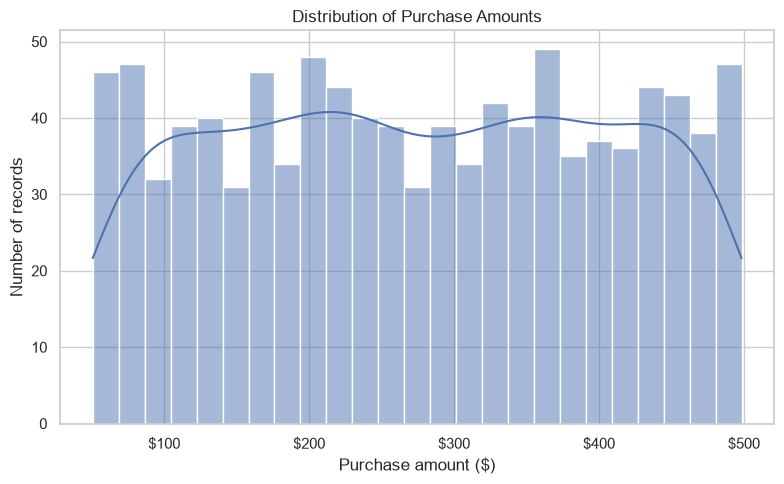

In [21]:
fig, ax = plt.subplots(figsize=(8,5))
sns.histplot(data = df, x= "Purchase_Amount", bins = 25, kde = True, ax=ax)
ax.set(title="Distribution of Purchase Amounts", xlabel="Purchase amount ($)", ylabel="Number of records")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"${value:,.0f}"))
fig.tight_layout()
plt.show()

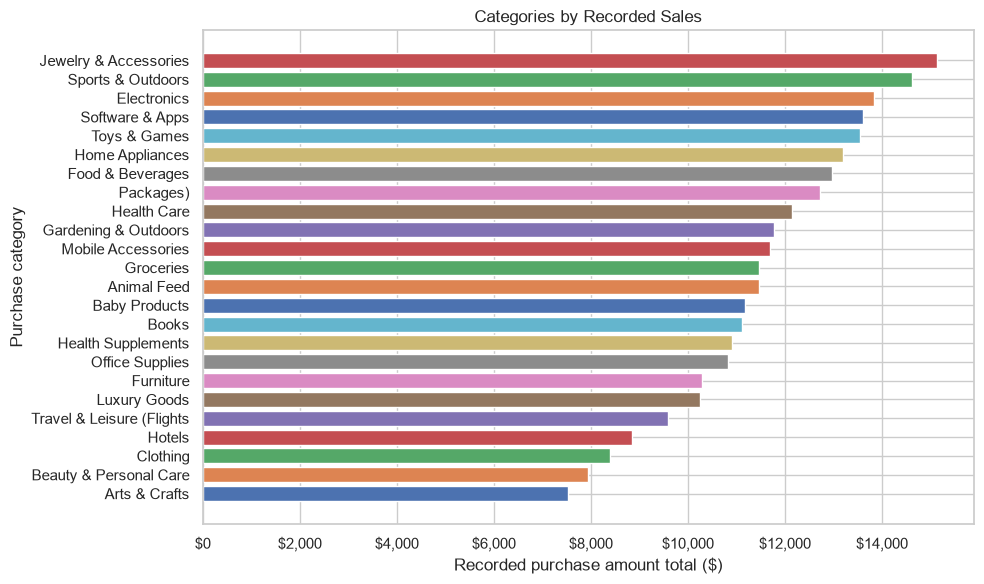

Top Sales caregory is Jewelry & Accessories


In [32]:
top_categories = category_summary.sort_values("total_sales")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_categories.index, top_categories["total_sales"], color=sns.color_palette("deep", len(top_categories)))
ax.set(title="Categories by Recorded Sales", xlabel="Recorded purchase amount total ($)", ylabel="Purchase category")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"${value:,.0f}"))
fig.tight_layout()

plt.show()

top_category = category_summary.iloc[0]
top_category_name = category_summary.index[0]

print(f"Top Sales caregory is {top_category_name}")

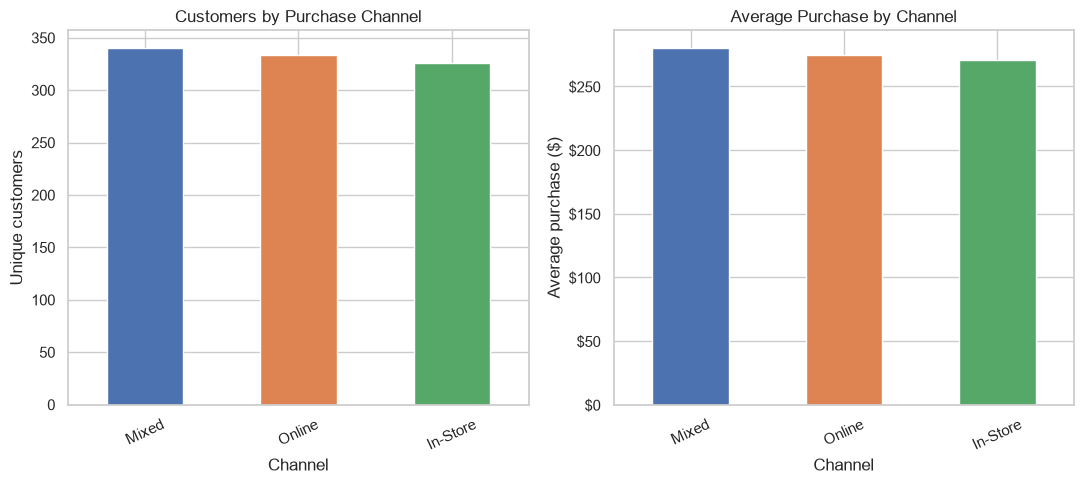

,customers,average_purchase
Purchase_Channel,,
Mixed,340,279.90
Online,334,274.26
In-Store,326,270.84


In [25]:
channel_summary = (
    df.groupby("Purchase_Channel")
    .agg(customers=("Customer_ID", "nunique"), average_purchase=("Purchase_Amount", "mean"))
    .sort_values("customers", ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
channel_summary["customers"].plot(kind="bar", ax=axes[0], color=sns.color_palette("deep", len(channel_summary)))
axes[0].set(title="Customers by Purchase Channel", xlabel="Channel", ylabel="Unique customers")
axes[0].tick_params(axis="x", rotation=25)
channel_summary["average_purchase"].plot(kind="bar", ax=axes[1], color=sns.color_palette("deep", len(channel_summary)))
axes[1].set(title="Average Purchase by Channel", xlabel="Channel", ylabel="Average purchase ($)")
axes[1].tick_params(axis="x", rotation=25)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"${value:,.0f}"))
fig.tight_layout()
plt.show()

display(channel_summary.round(2))

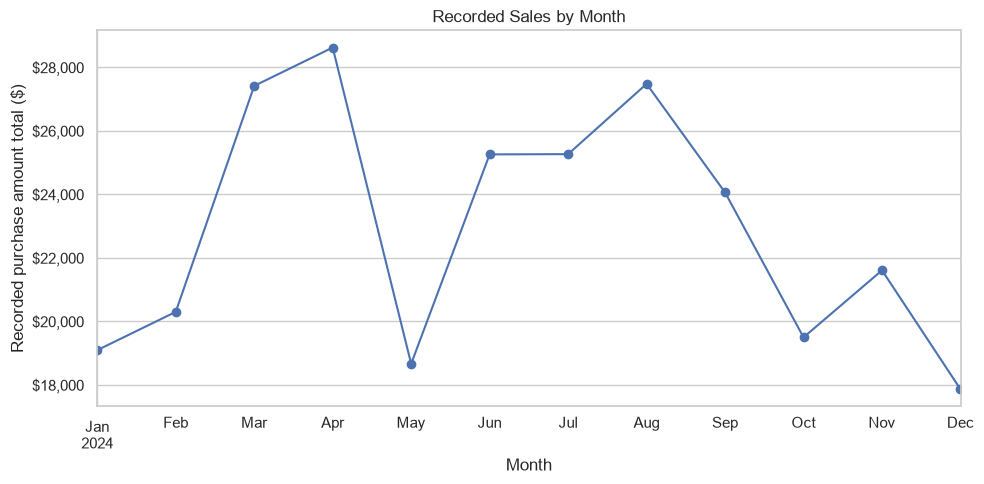

,recorded_sales
Time_of_Purchase,
2024-01-01,19089.22
2024-02-01,20294.28
2024-03-01,27409.79
2024-04-01,28617.22
2024-05-01,18658.99
2024-06-01,25253.23
2024-07-01,25260.62
2024-08-01,27473.39
2024-09-01,24054.76


In [26]:
monthly_sales = (
    df.set_index("Time_of_Purchase")["Purchase_Amount"]
    .resample("MS")
    .sum()
)

fig, ax = plt.subplots(figsize=(10, 5))
monthly_sales.plot(marker="o", ax=ax)
ax.set(title="Recorded Sales by Month", xlabel="Month", ylabel="Recorded purchase amount total ($)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"${value:,.0f}"))
fig.tight_layout()
plt.show()

display(monthly_sales.rename("recorded_sales").to_frame().round(2))